# 03 — Oscillator attention does associative recall (Fig 7, panel C / 图7C)

Panels A and B showed coupled oscillators *binding* observations (hand-built) and *scaling* to a
16,384-oscillator generative model (Un-0). Neither learns anything in the attention sense.
This notebook is about the third leg of Fig 7: **can a *learned* oscillator layer do the
job attention does?**

Everything below uses the installed `oscattn` package. Sources: `oscattn/assoc.py` (task),
`oscattn/models.py` (the two layers; its module docstring explains the maths),
`experiments/assoc_learning.py` (the full training protocol).

## Goal

**Question:** can a single attention layer built from coupled phase oscillators learn
*in-context associative recall* — the standard probe for attention
(Ba et al. 2016; Olsson et al. 2022)?

The task (`oscattn/assoc.py::make_batch`): each sequence lists 8 key→value pairs, then repeats one key
as a query; the target is the value that followed it.

```
k3 v17  k9 v2  k14 v30  ...  k9   ->  answer: v2
```

The pairings are drawn **fresh for every sequence**, so no fixed lookup table can be memorised — the
network must learn the *mechanism* "find where this key appeared, report what followed it".

- Keys: 32 distinct ids; values: 32 distinct ids.
- Chance = 1/32 ≈ **3%** (guessing a value id); picking a random value seen in the context ≈ 12.5%.

Below: one example batch, decoded.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import torch

from oscattn.assoc import make_batch

tokens, targets = make_batch(4, n_pairs=8, n_keys=32, n_vals=32,
                             generator=torch.Generator().manual_seed(0))
print("tokens shape:", tuple(tokens.shape), " (batch, 2*n_pairs + 1 query)")
print("targets shape:", tuple(targets.shape))

# Decode the first sequence: keys are ids 0..31, values are ids 32..63
seq, tgt = tokens[0].tolist(), targets[0].item()
pairs = [(seq[i], seq[i + 1]) for i in range(0, 16, 2)]
print("\nsequence 0:")
print("  pairs:", "  ".join(f"k{k}->v{v - 32}" for k, v in pairs))
print(f"  query key: k{seq[-1]}   target value: v{tgt - 32}")
ans = dict(pairs)[seq[-1]]
print(f"  check: the value that followed k{seq[-1]} is v{ans - 32}  (matches target: {ans == tgt})")
print(f"\nchance accuracy = 1/32 = {1/32:.3f}")

tokens shape: (4, 17)  (batch, 2*n_pairs + 1 query)
targets shape: (4,)

sequence 0:
  pairs: k12->v9  k27->v3  k2->v0  k3->v31  k18->v5  k13->v30  k28->v0  k19->v17
  query key: k2   target value: v0
  check: the value that followed k2 is v0  (matches target: True)

chance accuracy = 1/32 = 0.031


## Method — two attention layers, same interface, same size

Both layers live in `oscattn/models.py` behind the same interface (`Block`, `Model`: embedding →
1 layer → MLP → read the answer from the last (query) position). d = 64, 4 heads.

**SoftmaxAttention** — standard causal attention with RoPE position encoding: learned q/k/v
projections, `A = softmax(q kᵀ / √d)`, output `A v`.

**OscAttention** — each token is a set of `m = d/heads` phase oscillators per head
(module docstring of `oscattn/models.py`):

1. **Phases.** Each token gets phases `θ_i = atan2(W_s h_i, W_c h_i) + f_k · i` — a learned
   content phase (W_c, W_s play the role of W_q, W_k) plus a positional ramp with the *same
   frequencies as RoPE*, so both models receive identical position information.
2. **Coupling = lagged phase similarity.** `A_ij = softmax_j( β Σ_k w_k cos(θ_ik − θ_jk − α_k) )`,
   causal. The learned **phase lag α** (Kuramoto–Sakaguchi) makes coupling directional: token i
   couples most to a j that trails it by α — this is what can express "the value *follows* the key".
3. **Dynamics.** T = 4 steps of Kuramoto–Sakaguchi:
   `θ_ik ← θ_ik + dt · κ Σ_j A_ij sin(θ_jk + α_k − θ_ik)`, with `dt = 1.0`, recomputing A from the new
   phases each step — tokens that attend to each other lock (at lag α), and synchrony can spread.
4. **Readout.** Values are read **once**, from the final phases: `out_i = Σ_j A_ij(T) v_j`.

With T = 0 and α = 0 the oscillator layer degenerates to something like RoPE attention with
unit-amplitude tied q/k; the dynamics and the lag are the additions to be tested.

The design constraint: **same parameter count** — W_c, W_s replace W_q, W_k one for one.
Check it live:

In [2]:
from oscattn.models import Model, n_params

vocab = 64  # 32 keys + 32 values
softmax_1L = Model(vocab, d=64, heads=4, n_layers=1, kind='softmax')
osc_T4     = Model(vocab, d=64, heads=4, n_layers=1, kind='osc', steps=4, dt=1.0)
osc_T0     = Model(vocab, d=64, heads=4, n_layers=1, kind='osc', steps=0)              # no dynamics
osc_nolag  = Model(vocab, d=64, heads=4, n_layers=1, kind='osc', steps=4, dt=1.0,
                   learn_lag=False)                                                    # no phase lag

for name, m in [('softmax-1L', softmax_1L), ('osc-1L-T4', osc_T4),
                ('osc-1L-T0 (ablation)', osc_T0), ('osc-1L-T4-nolag (ablation)', osc_nolag)]:
    print(f"{name:28s} {n_params(m):,} parameters")
print(f"\noscillator vs softmax: {n_params(osc_T4)/n_params(softmax_1L) - 1:+.2%} (well within 1%)")

softmax-1L                   58,112 parameters
osc-1L-T4                    58,248 parameters
osc-1L-T0 (ablation)         58,248 parameters
osc-1L-T4-nolag (ablation)   58,248 parameters

oscillator vs softmax: +0.23% (well within 1%)


## Live mini-demo — the task is learnable end-to-end

Before loading the saved full-scale results, train the oscillator layer right here: **1,500 steps**
(batch 64, AdamW, lr 3e-3 — about 30 s on CPU, faster on GPU). This is a *demo*, not the result:
the real comparison uses 4,000 steps × 2 learning rates × 5 seeds and is loaded from disk in the next
section.

device: cuda


trained 1500 steps in 19s;  final test accuracy 0.992


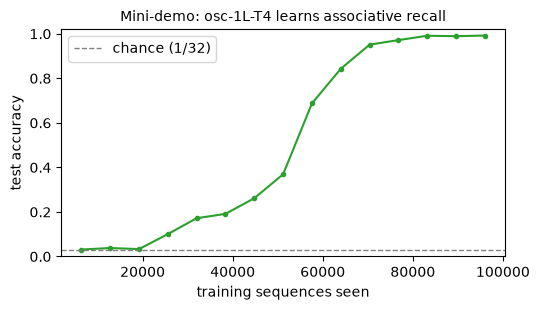

In [3]:
import time
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

torch.manual_seed(0)
model = Model(vocab, d=64, heads=4, n_layers=1, kind='osc', steps=4, dt=1.0).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 200))
data = torch.Generator().manual_seed(1000)          # fresh training stream
test = make_batch(1024, 8, 32, 32, generator=torch.Generator().manual_seed(7), device=device)

steps, curve = 1500, []
t0 = time.time()
for step in range(1, steps + 1):
    x, y = make_batch(64, 8, 32, 32, generator=data, device=device)
    loss = F.cross_entropy(model(x), y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % 100 == 0:
        model.eval()
        with torch.no_grad():
            acc = (model(test[0]).argmax(-1) == test[1]).float().mean().item()
        model.train()
        curve.append((step * 64, acc))
print(f"trained {steps} steps in {time.time() - t0:.0f}s;  final test accuracy {curve[-1][1]:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot([c[0] for c in curve], [c[1] for c in curve], 'o-', ms=3, color='C2')
ax.axhline(1 / 32, color='gray', ls='--', lw=1, label='chance (1/32)')
ax.set_xlabel('training sequences seen'); ax.set_ylabel('test accuracy')
ax.set_title('Mini-demo: osc-1L-T4 learns associative recall', fontsize=10)
ax.set_ylim(0, 1.02); ax.legend(); fig.tight_layout()

## Result — the full comparison (saved runs, panel C)

The demo above is one seed and a short run. Fig 7 uses
`experiments/assoc_learning.py` with the full protocol (`results/assoc_p8.json`):

- 4,000 steps (256k sequences), batch 64, AdamW, lr ∈ {1e-3, 3e-3}, **5 seeds**;
- every model sees the **same data stream** (same seed → same sequences) and is scored on the same
  held-out test set;
- per model, the lr is picked by one rule for everyone (best mean final accuracy);
- **four models**: `softmax-1L`, `osc-1L-T4`, and the two ablations —
  `osc-1L-T0` (dynamics switched off) and `osc-1L-T4-nolag` (lag α frozen at 0, symmetric coupling).

One bar per model (mean over seeds), one dot per seed:

loaded 60 runs  (protocol: steps=4000, seeds=5, lrs=[0.001, 0.003])
softmax-1L       (lr 0.001)  mean 0.207   seeds ['0.206', '0.216', '0.207', '0.203', '0.202']
osc-1L-T4        (lr 0.001)  mean 0.997   seeds ['0.999', '0.995', '0.999', '1.000', '0.994']
osc-1L-T0        (lr 0.001)  mean 0.207   seeds ['0.205', '0.208', '0.209', '0.208', '0.206']
osc-1L-T4-nolag  (lr 0.003)  mean 0.894   seeds ['0.892', '0.869', '0.891', '0.911', '0.906']


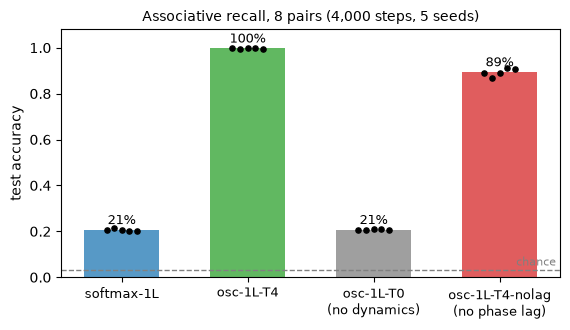

In [4]:
import json
from pathlib import Path

import numpy as np

ROOT = Path('..') if Path('.').resolve().name == 'notebooks' else Path('.')  # works from repo root or notebooks/
data = json.loads((ROOT / 'results' / 'assoc_p8.json').read_text())
runs = data['runs']
print(f"loaded {len(runs)} runs  (protocol: steps={data['args']['steps']}, "
      f"seeds={data['args']['seeds']}, lrs={data['args']['lrs']})")

MODELS = ['softmax-1L', 'osc-1L-T4', 'osc-1L-T0', 'osc-1L-T4-nolag']
LABELS = ['softmax-1L', 'osc-1L-T4', 'osc-1L-T0\n(no dynamics)', 'osc-1L-T4-nolag\n(no phase lag)']
COLORS = ['C0', 'C2', 'C7', 'C3']

means, seeds = [], []
for name in MODELS:
    mruns = [r for r in runs if r['model'] == name]
    best_lr = max({r['lr'] for r in mruns},
                  key=lambda lr: np.mean([r['final_acc'] for r in mruns if r['lr'] == lr]))
    accs = [r['final_acc'] for r in mruns if r['lr'] == best_lr]
    means.append(np.mean(accs)); seeds.append(accs)
    print(f"{name:16s} (lr {best_lr:g})  mean {np.mean(accs):.3f}   "
          f"seeds {['%.3f' % a for a in accs]}")

fig, ax = plt.subplots(figsize=(5.8, 3.4))
bars = ax.bar(range(4), means, color=COLORS, alpha=0.75, width=0.6)
for i, accs in enumerate(seeds):
    ax.scatter(np.full(len(accs), i) + np.linspace(-0.12, 0.12, len(accs)), accs,
               color='black', s=14, zorder=3)
for i, m in enumerate(means):
    ax.text(i, m + 0.025, f'{m * 100:.0f}%', ha='center', fontsize=9)
ax.axhline(1 / 32, color='gray', ls='--', lw=1)
ax.text(3.45, 1 / 32 + 0.02, 'chance', color='gray', fontsize=8, ha='right')
ax.set_xticks(range(4)); ax.set_xticklabels(LABELS, fontsize=9)
ax.set_ylabel('test accuracy'); ax.set_ylim(0, 1.08)
ax.set_title('Associative recall, 8 pairs (4,000 steps, 5 seeds)', fontsize=10)
fig.tight_layout()

## Takeaway

- **A single learned oscillator attention layer solves in-context associative recall**: 99.5% mean
  accuracy, where a single softmax attention layer of the *same size, same position encoding, same
  data stream* stays at 21%. This is panel C of Fig 7 (图7C).
- **Both oscillator ingredients are necessary**: switching off the dynamics (T=0) collapses the model
  to softmax-1L-level performance (~21%, never above ~25%), and freezing the phase lag α at 0
  (symmetric coupling) caps it at ~89% — it learns, but never reaches the 95% criterion. The lag is
  what lets the layer express direction ("the value *follows* the key").
- **Caveat — this is not the full comparison.** The fair control for "one layer + internal iteration"
  is a softmax layer *looped* 4× with shared weights, which learns the task about **1.9× faster** than
  the oscillator (51k vs 96k sequences to 95%): the oscillator beats one-shot attention, not iterated
  attention. That comparison, plus the length-generalisation fix (`static_query`) and the rhythm-task
  negative result, is in **notebook 04**.
- The mechanism (how the query's phase coupling to the answer grows over the 4 dynamics steps) is
  measured in `experiments/assoc_mechanism.py` → `results/assoc_mechanism*.png`.